# Landmark observations — overlay

Each detection's landmark from `landmarks/<seq>/<backend>.npz`: a Gaussian over
the object's map-frame position. Green = a landmark was found, red = the bbox
enclosed no usable keypoint, so the detection carries none.

Per box: `·` kept keypoints, `×` rejected as a depth outlier (mostly raised leaf
tips, nearer than the plant body), `+` the landmark centre reprojected, and the ellipse its 1-sigma **extent** — the
object's physical spread, not the (much tighter) uncertainty about its centre.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse

ROOT = Path.cwd()
if ROOT.name == "lab":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "landmarks"))

from mapsort.data import sequence
from sfm_mapping import depth_inliers, read_dets, read_keypoints, read_points3D

SEQ, BACKEND, SPLIT = "0011", "sfm", "test"

seq = sequence("lettucemots", SPLIT, SEQ)
model = ROOT / "data/lettucemots/recon" / SEQ / "model_txt"

lm = dict(np.load(seq.landmark_path(BACKEND)))
keypoints = read_keypoints(model / "images.txt")
points3D = read_points3D(model / "points3D.txt")
frames, det_idx, boxes = read_dets(seq.dets_path)
images = {i + 1: p for i, p in enumerate(seq.image_paths())}

cam = [l.split() for l in (model / "cameras.txt").read_text().splitlines() if not l.startswith("#")][0]
focal, cx, cy = float(cam[4]), float(cam[5]), float(cam[6])

assert len(frames) == len(lm["has_landmark"]), "landmarks and dets are out of step"
print(f"{SEQ}: {len(frames)} dets, {lm['has_landmark'].sum()} with a landmark")

0011: 3073 dets, 3032 with a landmark


## Overlay

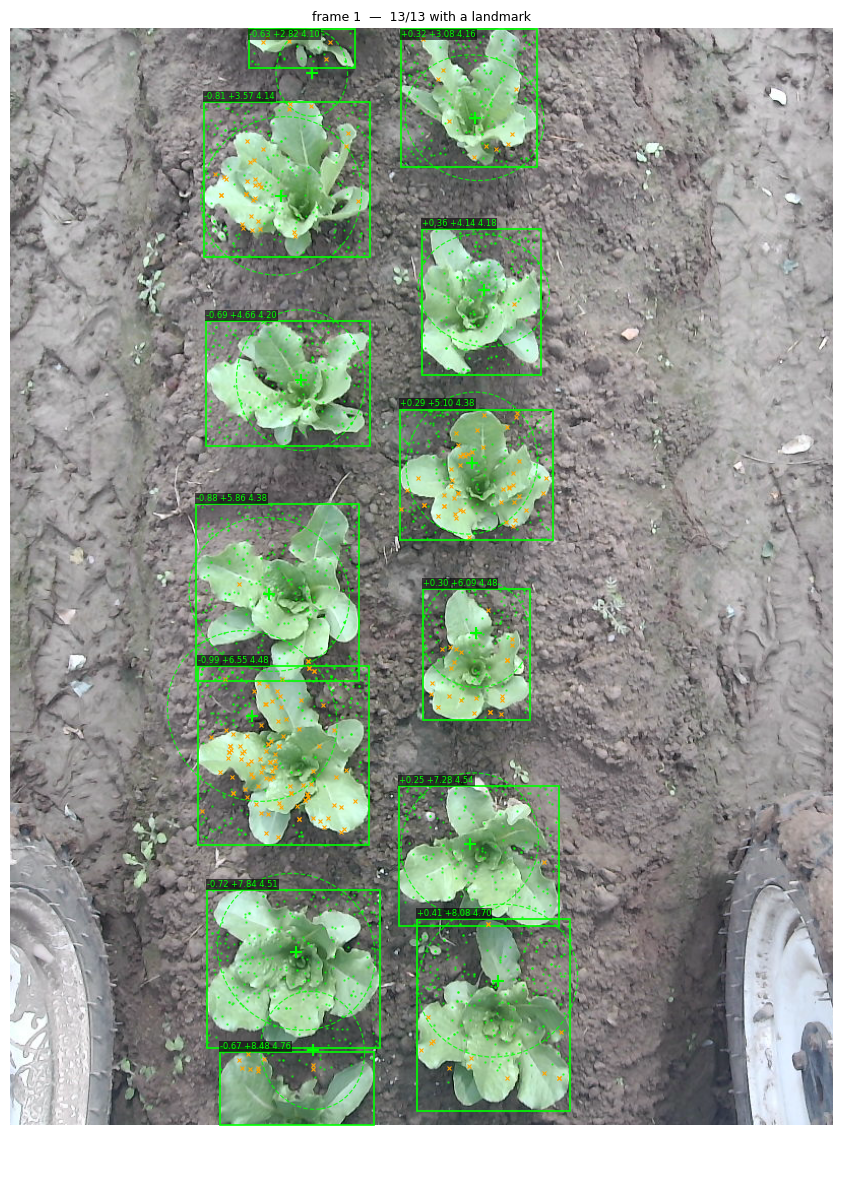

In [2]:
def project(X, R, t):
    """World points to pixels (radial distortion ignored)."""
    c = np.atleast_2d(X) @ R.T + t
    return np.column_stack([focal * c[:, 0] / c[:, 2] + cx, focal * c[:, 1] / c[:, 2] + cy]), c


def overlay(frame_no, ax=None, fontsize=6, sigma=1.0):
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 12))
    ax.imshow(cv2.cvtColor(cv2.imread(str(images[frame_no])), cv2.COLOR_BGR2RGB))

    xy, ids, R, t = keypoints[images[frame_no].name]
    rows = np.flatnonzero(frames == frame_no)

    for i in rows:
        bbox, found = boxes[i], lm["has_landmark"][i]
        colour = "lime" if found else "red"
        x0, y0, x1, y1 = bbox
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=colour, lw=1.2))

        inside = np.all((xy >= bbox[:2]) & (xy <= bbox[2:]), axis=1)
        if inside.any():
            pts = np.array([points3D[j] for j in ids[inside]])
            keep = depth_inliers((pts @ R.T + t)[:, 2])
            ax.plot(*xy[inside][keep].T, ".", color=colour, ms=1.5, alpha=0.6)
            ax.plot(*xy[inside][~keep].T, "x", color="orange", ms=3, mew=0.8)

        if not found:
            ax.text(x0, max(y0 - 3, 8), "no landmark", color=colour, fontsize=fontsize,
                    bbox=dict(fc="black", alpha=0.6, pad=0.7, lw=0))
            continue

        p = lm["position"][i]
        uv, cam_pt = project(p, R, t)
        ax.plot(*uv[0], "+", color=colour, ms=9, mew=1.5)

        # First-order propagation of the world-frame extent into the image.
        x, y, z = cam_pt[0]
        J = focal / z * np.array([[1, 0, -x / z], [0, 1, -y / z]])
        C = J @ (R @ lm["extent"][i] @ R.T) @ J.T
        vals, vecs = np.linalg.eigh(C)
        vals = np.clip(vals, 0, None)
        ax.add_patch(Ellipse(uv[0], *(2 * sigma * np.sqrt(vals)),
                             angle=np.degrees(np.arctan2(*vecs[::-1, 1])),
                             fill=False, ec=colour, lw=0.9, ls="--", alpha=0.8))

        ax.text(x0, max(y0 - 3, 8), f"{p[0]:+.2f} {p[1]:+.2f} {p[2]:.2f}", color=colour,
                fontsize=fontsize, bbox=dict(fc="black", alpha=0.6, pad=0.7, lw=0))

    found = int(lm["has_landmark"][rows].sum())
    ax.set_title(f"frame {frame_no}  —  {found}/{len(rows)} with a landmark", fontsize=9)
    ax.axis("off")
    return ax


overlay(1)
plt.tight_layout()

Frames with the most missing landmarks — where the method fails.

worst frames: [23, 107, 136, 11, 24, 28, 31, 32]


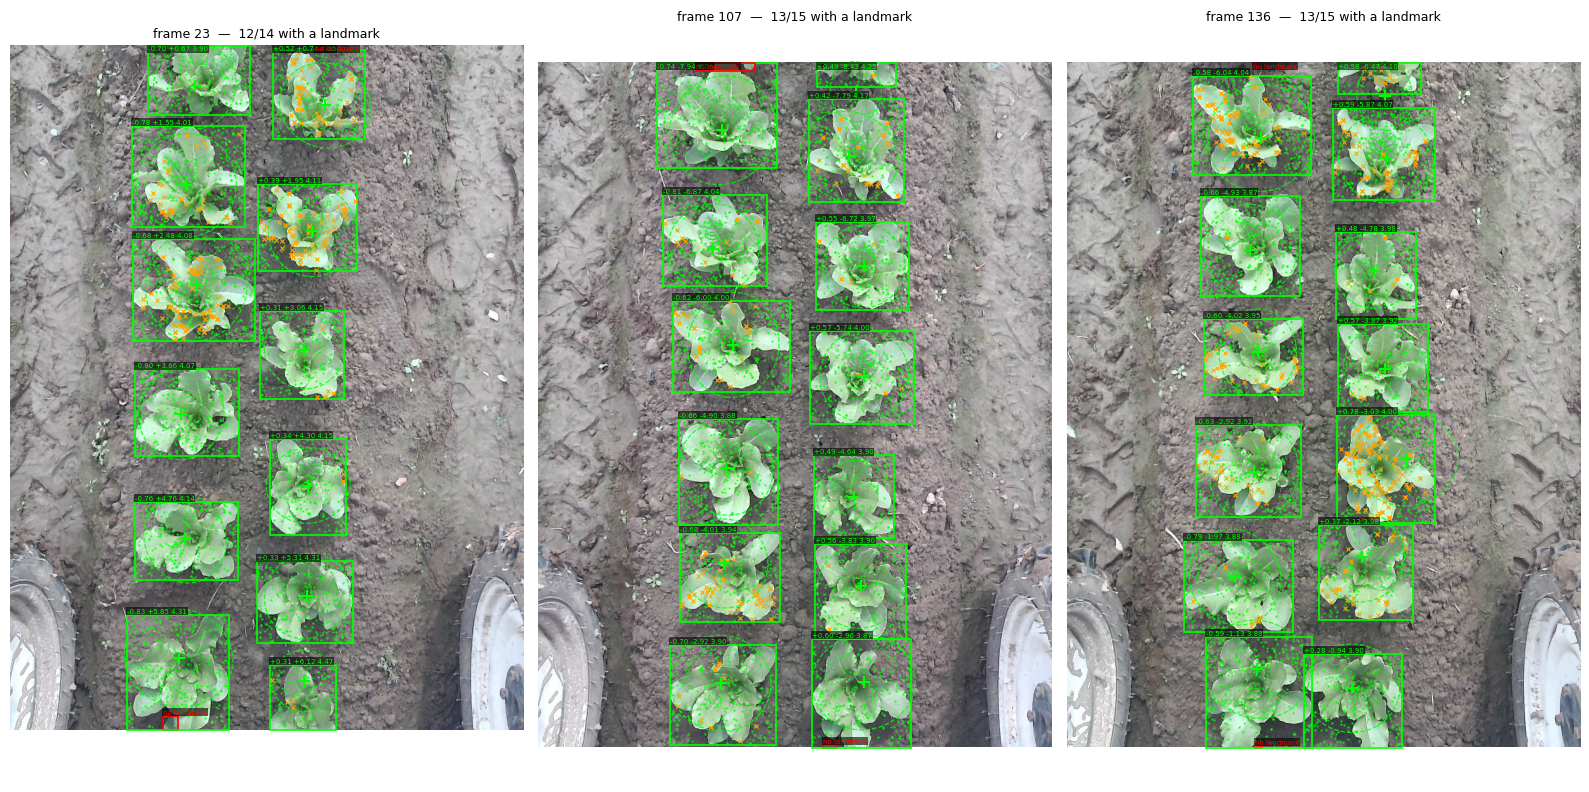

In [3]:
per_frame = {f: np.flatnonzero(frames == f) for f in np.unique(frames)}
worst = sorted(per_frame, key=lambda f: -int((~lm["has_landmark"][per_frame[f]]).sum()))
print("worst frames:", worst[:8])

fig, axes = plt.subplots(1, 3, figsize=(16, 8))
for ax, frame_no in zip(axes, worst[:3]):
    overlay(frame_no, ax=ax, fontsize=5)
plt.tight_layout()

## Extent is not uncertainty

`extent` is the plant's physical spread and stays put; `covariance` is the
uncertainty about its centre and shrinks as `extent / n_kept`. Fusing the wrong
one across observations would claim precision finer than the plant itself.

ratio extent/centre: 15.3 x


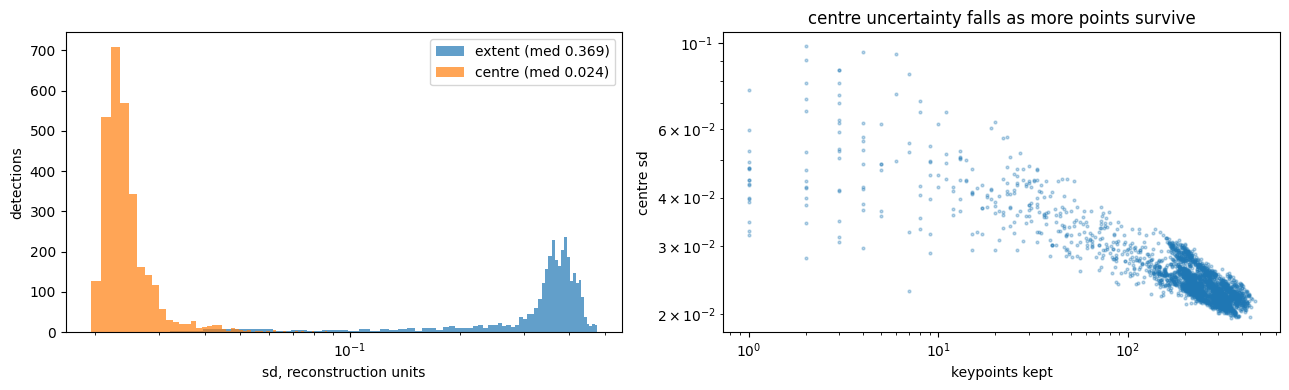

In [4]:
h = lm["has_landmark"]
sd_ext = np.sqrt(np.array([np.diag(e) for e in lm["extent"][h]]))
sd_cov = np.sqrt(np.array([np.diag(c) for c in lm["covariance"][h]]))

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.hist(sd_ext.mean(1), bins=60, alpha=0.7, label=f"extent (med {np.median(sd_ext):.3f})")
a.hist(sd_cov.mean(1), bins=60, alpha=0.7, label=f"centre (med {np.median(sd_cov):.3f})")
a.set(xlabel="sd, reconstruction units", ylabel="detections", xscale="log")
a.legend()

b.scatter(lm["n_kept"][h], sd_cov.mean(1), s=4, alpha=0.3)
b.set(xlabel="keypoints kept", ylabel="centre sd", xscale="log", yscale="log",
      title="centre uncertainty falls as more points survive")
plt.tight_layout()
print("ratio extent/centre:", round(float(np.median(sd_ext) / np.median(sd_cov)), 1), "x")

## The map

Top-down `XY` coloured by frame. The two crop rows should separate and the
along-row spread grow with frame as the camera drives.

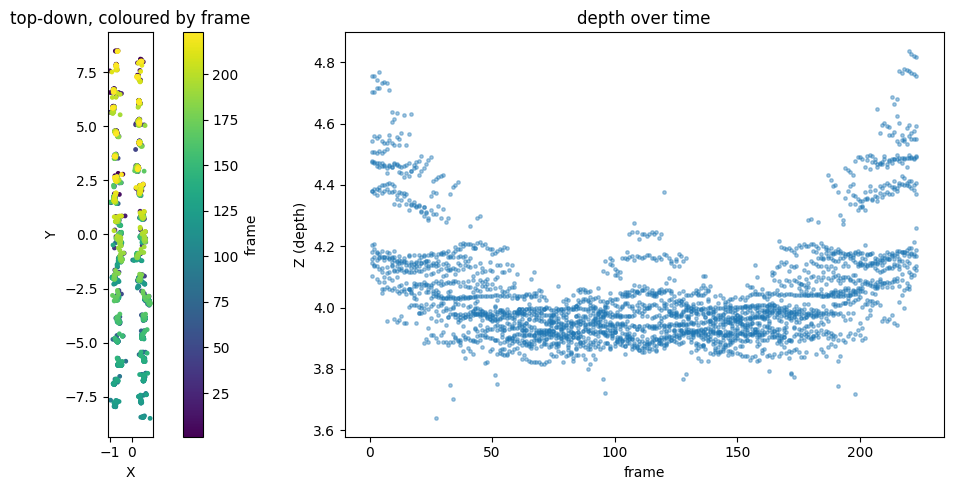

In [5]:
pos, fr = lm["position"][h], lm["frame"][h]

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5))
s = a.scatter(pos[:, 0], pos[:, 1], c=fr, s=6, cmap="viridis")
a.set(xlabel="X", ylabel="Y", title="top-down, coloured by frame")
a.set_aspect("equal")
fig.colorbar(s, ax=a, label="frame")

b.scatter(fr, pos[:, 2], s=6, alpha=0.4)
b.set(xlabel="frame", ylabel="Z (depth)", title="depth over time")
plt.tight_layout()